In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [13]:
file_path = "/kaggle/input/datasets/farhankarim11/climate-records-of-gilgit/Climate records of Gilgit.csv"

In [14]:
df = pd.read_csv(file_path)

In [15]:
df.columns = df.columns.str.strip()

In [16]:
df_monthly = df[df['Month'] != 'Annual'].copy()

In [17]:
X = df_monthly[['Lowest Minimum Temperature in Celsius']]
y = df_monthly['Highest Maximum Temperature in Celsius']

In [18]:
model = LinearRegression()
model.fit(X, y)

LinearRegression()

In [19]:
y_pred = model.predict(X)
slope = model.coef_[0]
intercept = model.intercept_
r2 = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))

In [20]:
print("=" * 40)
print("  SIMPLE LINEAR REGRESSION RESULTS")
print("=" * 40)
print(f"Regression Equation : y = {slope:.4f} * x + {intercept:.4f}")
print(f"R-squared (R²)      : {r2:.4f}")
print(f"RMSE                : {rmse:.4f}")
print("=" * 40)

  SIMPLE LINEAR REGRESSION RESULTS
Regression Equation : y = 1.2136 * x + 35.6320
R-squared (R²)      : 0.8996
RMSE                : 2.9144


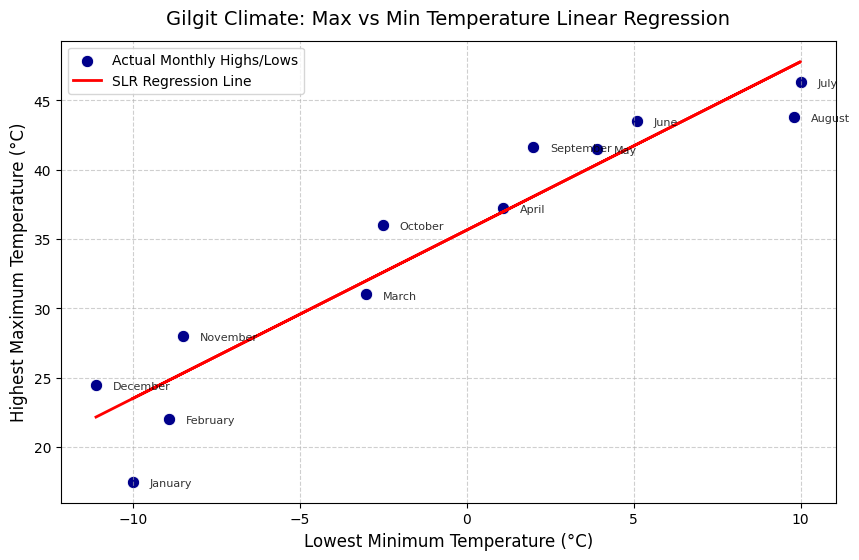

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Lowest Minimum Temperature in Celsius', 
                y='Highest Maximum Temperature in Celsius', 
                data=df_monthly, color='darkblue', s=80, label='Actual Monthly Highs/Lows')

plt.plot(df_monthly['Lowest Minimum Temperature in Celsius'], y_pred, color='red', linewidth=2, label='SLR Regression Line')

# Annotate points with Month names
for i, txt in enumerate(df_monthly['Month']):
    plt.annotate(txt, (X.iloc[i, 0] + 0.5, y.iloc[i] - 0.3), fontsize=8, alpha=0.8)

plt.title('Gilgit Climate: Max vs Min Temperature Linear Regression', fontsize=14, pad=12)
plt.xlabel('Lowest Minimum Temperature (°C)', fontsize=12)
plt.ylabel('Highest Maximum Temperature (°C)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()